In [1]:
import itertools, numpy as np, jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)
import flax.linen as nn
import netket as nk
from netket.experimental.geometry import SphereN
import netket.experimental.operator.spin_manifold as sp_man
import netket.operator.spin as nk_op
from netket.sampler.rules import SphereGaussianRule

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
/home/grovert4/TPIV/project/.venv313/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


∣NK⟩ Tip: nk.symmetry.spin_flip_representation(hi).project(vstate, 0) to make it spin-flip symmetric.

In [2]:
class Multilinear(nn.Module):
    @nn.compact
    def __call__(self, x):
        alpha = self.param("alpha", lambda k, s: (jax.random.normal(k, s)+0j), (2**N,))
        q = x.reshape(x.shape[:-1]+(N,4))
        up = q[...,0]+1j*q[...,3]; dn = q[...,2] + 1j*q[...,1]
        tot = 0
        for idx,n in enumerate(itertools.product([0,1],repeat=N)):
            term = alpha[idx]
            for k in range(N):
                term = term*(up[...,k] if n[k]==0 else dn[...,k])
            tot = tot+term
        return jnp.log(tot)

In [3]:
N = 4
Gammas =  jnp.linspace(-0.2, -2.0, 11)
n_iter = 300
learning_rate = 0.05
diag_shift = 0.01
n_samples = 1024
n_chains = 16
n_discard = 64
sweep_size = 1
n_samples_obs = 8192
V = -1
sigma = 1.5

In [5]:
def ising1d_energy(L, h):
    k = np.pi * (2 * np.arange(L) + 1) / L
    return -np.sum(np.sqrt(1 + h**2 + 2 * h * np.cos(k)))

def config_observables(H, hi, vs):
    n_sites = hi.n_particles
    alpha = np.asarray(vs.parameters["alpha"])
    if alpha.shape != (2**n_sites,):
        raise ValueError(f"Expected 2**{n_sites} amplitudes, got shape {alpha.shape}")
    norm = np.linalg.norm(alpha)
    if not np.isfinite(norm) or norm == 0:
        raise ValueError("The variational-state amplitudes must have a finite, non-zero norm")
    phi = alpha / norm

    sigma_z = np.diag([1, -1]).astype(complex)
    sigma_x = np.array([[0, 1], [1, 0]], dtype=complex)

    def site_op(matrix, site):
        factors = [np.eye(2, dtype=complex) for _ in range(n_sites)]
        factors[site] = matrix
        result = factors[0]
        for factor in factors[1:]:
            result = np.kron(result, factor)
        return result

    Mz_op = sum(site_op(sigma_z, i) for i in range(n_sites)) / n_sites
    Mx_op = sum(site_op(sigma_x, i) for i in range(n_sites)) / n_sites
    Mz2_op = Mz_op @ Mz_op
    abs_Mz_op = np.diag(np.abs(np.diag(Mz_op)))

    def expectation(operator):
        return float(np.real(phi.conj() @ operator @ phi))

    mz = expectation(Mz_op)
    abs_mz = expectation(abs_Mz_op)
    mz2 = expectation(Mz2_op)
    energy = float(np.real(vs.expect(H).mean))

    return {
        "energy": energy,
        "Mz": mz,
        "Mx": expectation(Mx_op),
        "abs_Mz": abs_mz,
        "Mz2": mz2,
        "chi": n_sites * (mz2 - abs_mz**2),
    }

In [ ]:
def run_VMC(Gamma):
    hi = nk.experimental.hilbert.Particle(N=N, geometry=SphereN(3))
    H = 0
    for i in range(N):
        H += V*sp_man.sigmaz(hi,i) @ sp_man.sigmaz(hi,(i+1)%N)
        H += float(Gamma)*sp_man.sigmax(hi,i)
    
    sa = nk.sampler.MetropolisSampler(hi, SphereGaussianRule(sigma=sigma), n_chains=n_chains, sweep_size=sweep_size)
    vs = nk.vqs.MCState(sa, Multilinear(), n_samples=n_samples, n_discard_per_chain=n_discard, seed=67)
    
    opt = nk.optimizer.Sgd(learning_rate=learning_rate)
    gs = nk.driver.VMC(H, opt, variational_state=vs, preconditioner=nk.optimizer.SR(diag_shift=diag_shift, holomorphic=True))
    gs.run(n_iter=n_iter, show_progress=False)
    vs.n_samples = n_samples_obs
    
    res = config_observables(H, hi, vs)
    return [res,vs] 

In [10]:
results = []
v_states = []
for G in Gammas:
    res_t, vs_t = run_VMC(G)
    results.append(res_t)
    v_states.append(vs_t)

ValueError: Site 4 out of range.

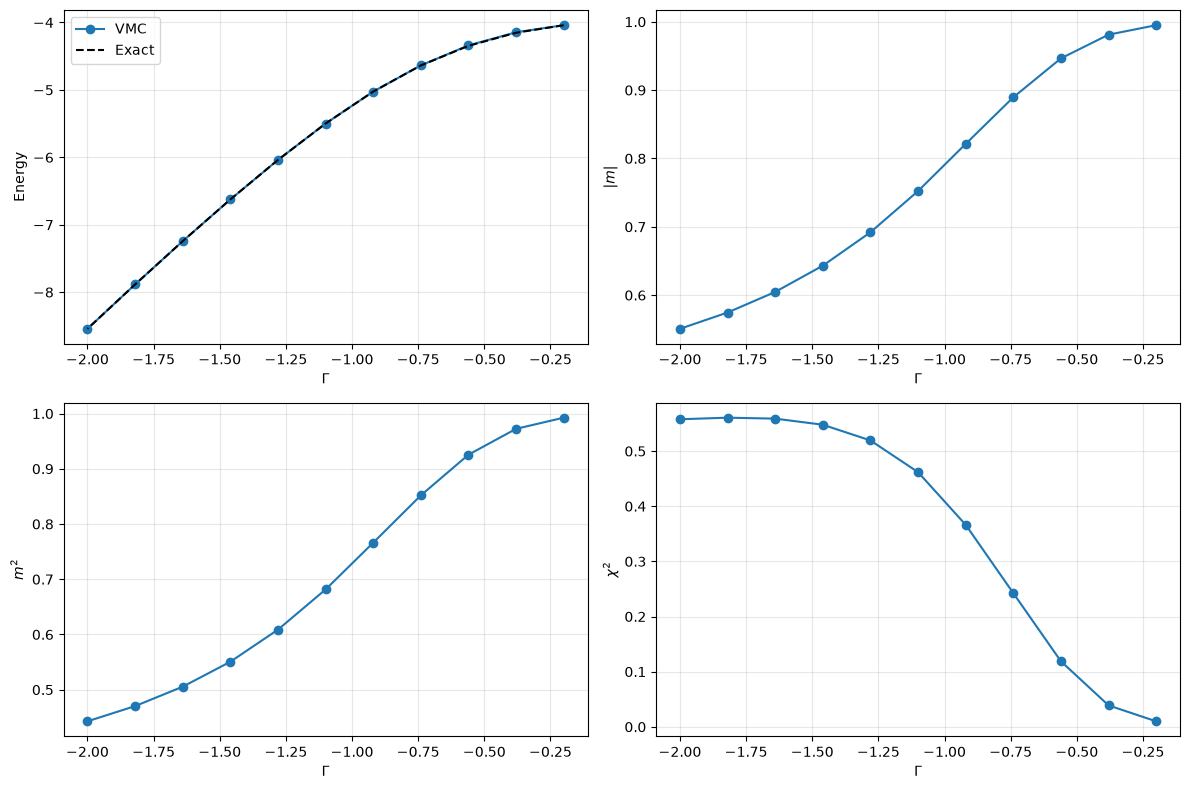

In [8]:
import matplotlib.pyplot as plt

gamma_values = np.asarray(Gammas, dtype=float)
energy = np.array([result["energy"] for result in results])
energy_exact = np.array([ising1d_energy(N, float(G) / V) for G in gamma_values])
abs_m = np.array([result["abs_Mz"] for result in results])
m_squared = np.array([result["Mz2"] for result in results])
chi_squared = np.array([result["chi"] for result in results])

fig, axs = plt.subplots(2, 2, figsize=(12, 8))
axs[0, 0].plot(gamma_values, energy, "o-", label="VMC")
axs[0, 0].plot(gamma_values, energy_exact, "k--", label="Exact")
axs[0, 0].set_ylabel("Energy")
axs[0, 0].legend()

axs[0, 1].plot(gamma_values, abs_m, "o-")
axs[0, 1].set_ylabel(r"$|m|$")

axs[1, 0].plot(gamma_values, m_squared, "o-")
axs[1, 0].set_ylabel(r"$m^2$")
    
axs[1, 1].plot(gamma_values, chi_squared, "o-")
axs[1, 1].set_ylabel(r"$\chi^2$")

for ax in axs.flat:
    ax.set_xlabel(r"$\Gamma$")
    ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.savefig("Thermodynamic quantities")

0.12.0.1
